# Minimum-Error Quantum State Discrimination via Semidefinite Programming (SDP)
### Modern Implementation & Generalization based on Wang et al. (CCC 2008), Helstrom (1976), and Yuen-Kennedy-Lax (1975)

---

## 1. Problem Formulation & Theoretical Foundations

In quantum information and quantum communication, non-orthogonal quantum states cannot be distinguished with certainty. 
Suppose a sender (Alice) transmits a quantum system prepared in one of $m$ possible states described by density operators $\{\rho_j\}_{j=1}^m$ with known prior probabilities $\{\xi_j\}_{j=1}^m$ ($\sum_{j=1}^m \xi_j = 1$).

The receiver (Bob) seeks an optimal measurement strategy—a Positive Operator-Valued Measure (**POVM**) $\{\Pi_j\}_{j=1}^m$—satisfying:
1. **Positivity**: $\Pi_j \succeq 0 \quad \forall j \in \{1, \dots, m\}$
2. **Completeness**: $\sum_{j=1}^m \Pi_j = I_n$

### Primal SDP Formulation
The average probability of correct detection $P_s$ is:
$$\max_{\{\Pi_j\}} P_s = \sum_{j=1}^m \xi_j \mathrm{Tr}(\Pi_j \rho_j) = \sum_{j=1}^m \mathrm{Tr}(\Pi_j \rho'_j)$$
where $\rho'_j = \xi_j \rho_j$.

### Dual SDP Formulation
$$\min_X \mathrm{Tr}(X) \quad \text{subject to} \quad X \succeq \rho'_j \quad \forall j \in \{1, \dots, m\}, \quad X = X^\dagger$$

### Yuen-Kennedy-Lax (YKL) / Holevo-Helstrom Optimality Conditions
A POVM set $\{\Pi_j\}$ is globally optimal if and only if the Hermitian operator $X = \sum_{j=1}^m \Pi_j \rho'_j = \sum_{j=1}^m \rho'_j \Pi_j$ satisfies:
1. **Dual Feasibility (No-Go Slack)**: $X - \rho'_j \succeq 0 \quad \forall j \in \{1, \dots, m\}$
2. **Complementary Slackness**: $(X - \rho'_j)\Pi_j = 0 \quad \forall j \in \{1, \dots, m\}$

---


## 2. Environment Setup & Modern Library Stack

We utilize modern quantum information and optimization libraries:
- **CVXPY 1.9+**: Modern convex optimization framework with complex Hermitian cone constraints (`>> 0`).
- **Toqito 1.3+**: Theory of Quantum Information Toolkit for specialized quantum SDPs.
- **QuTiP 5.3+**: Standard Python framework for quantum dynamics and state representations.
- **NumPy & SciPy**: High-performance linear algebra and matrix spectral decompositions.
- **Matplotlib & IPyWidgets**: Rich interactive visualizations, 3D Bloch sphere projections, and live parameter sweeps.


In [1]:
import importlib.metadata
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
import cvxpy as cp
import qutip as qt
import toqito
import ipywidgets as widgets
from IPython.display import display

# Import our modular Quantum State Discrimination package
from quantum_state_discrimination import (
    QuantumStateDiscriminator,
    states,
    visualization
)

print(f"NumPy version:   {np.__version__}")
print(f"CVXPY version:   {cp.__version__}")
print(f"Toqito version:  {importlib.metadata.version('toqito')}")
print(f"QuTiP version:   {qt.__version__}")


NumPy version:   2.5.2
CVXPY version:   1.9.2
Toqito version:  1.3.1
QuTiP version:   5.3.1


## 3. Benchmark: Reproducing Section 5 of the 2008 Paper (Wang et al.)

In Section 5 of the paper, the authors consider 3 pure qubit states:
$$|\phi_1\rangle = \begin{pmatrix} 1 \\ 0 \end{pmatrix}, \quad |\phi_2\rangle = \frac{1}{\sqrt{2}}\begin{pmatrix} 1 \\ 1 \end{pmatrix}, \quad |\phi_3\rangle = \begin{pmatrix} 0 \\ 1 \end{pmatrix}$$
with prior probabilities $\xi = [0.1, 0.6, 0.3]$.

Using MATLAB 7.0 and SeDuMi 1.05 in 2008, the authors obtained:
- Optimal Success Probability: $P_s \approx 0.785410$
- Optimal Detection Operators: $\Pi_1 = 0$, $\Pi_2 = \begin{pmatrix} 0.7236 & 0.4472 \\ 0.4472 & 0.2764 \end{pmatrix}$, $\Pi_3 = \begin{pmatrix} 0.2764 & -0.4472 \\ -0.4472 & 0.7236 \end{pmatrix}$

Let's solve this using our modern `QuantumStateDiscriminator` class across **CVXPY**, **Toqito**, and the **Paper's Standard SDP formulation**.


In [2]:
# 1. Load benchmark states and priors
raw_states, probs = states.paper_2008_states()

# 2. Instantiate dynamic discriminator
discriminator = QuantumStateDiscriminator(states=raw_states, probabilities=probs)

# 3. Solve with modern CVXPY SDP
result_cvxpy = discriminator.solve(method="cvxpy")

# 4. Display formatted summary
visualization.display_results_summary(result_cvxpy)


  QUANTUM STATE DISCRIMINATION RESULTS (CVXPY (CLARABEL))
Hilbert Space Dimension (n):       2
Number of Quantum States (m):      3
Optimal Success Probability (Ps):   0.785410 (78.54%)
Minimum Error Probability (Pe):     0.214590 (21.46%)
Duality Gap:                       8.88e-11
Optimality Verification (YKL):     PASSED (Globally Optimal)
-----------------------------------------------------------------
Prior Probabilities xi:
  [0.1, 0.6, 0.3]
-----------------------------------------------------------------
Optimal POVM Measurement Operators {Pi_j}:

POVM Pi_1 (Trace = 0.0000):
[[ 0.+0.j -0.+0.j]
 [-0.+0.j  0.+0.j]]

POVM Pi_2 (Trace = 1.0000):
[[0.7236+0.j 0.4472+0.j]
 [0.4472+0.j 0.2764+0.j]]

POVM Pi_3 (Trace = 1.0000):
[[ 0.2764+0.j -0.4472+0.j]
 [-0.4472+0.j  0.7236+0.j]]


### Cross-Verification with Multiple Solvers
Let's compare the results across **Modern CVXPY**, **Toqito (Quantum IT library)**, and the **Paper's Standard Block SDP Formulation (Theorem 1)**:


In [3]:
# Solve via Toqito
result_toqito = discriminator.solve(method="toqito")

# Solve via Paper's Standard Block SDP (Theorem 1)
result_std = discriminator.solve(method="standard_sdp")

print(f"{'Solver / Method':<42} | {'Success Prob (Ps)':<18} | {'Duality Gap':<12} | {'Optimal?'}")
print("-" * 85)
for res in [result_cvxpy, result_toqito, result_std]:
    print(f"{res.solver_name:<42} | {res.success_probability:<18.8f} | {res.duality_gap:<12.2e} | {res.is_optimal}")


Solver / Method                            | Success Prob (Ps)  | Duality Gap  | Optimal?
-------------------------------------------------------------------------------------
CVXPY (CLARABEL)                           | 0.78541020         | 8.88e-11     | True
Toqito (cvxopt)                            | 0.78541019         | 0.00e+00     | True
Standard Block SDP (Paper 2008 formulation) | 0.78541020         | 0.00e+00     | True


### Visualizing Optimality Conditions (Dual Feasibility & Complementary Slackness)
The Yuen-Kennedy-Lax (YKL) optimality conditions require:
1. **$X - \rho'_j \succeq 0$**: All eigenvalues of the slack matrices must be non-negative.
2. **$(X - \rho'_j)\Pi_j = 0$**: The complementary slackness Frobenius norm must be zero.


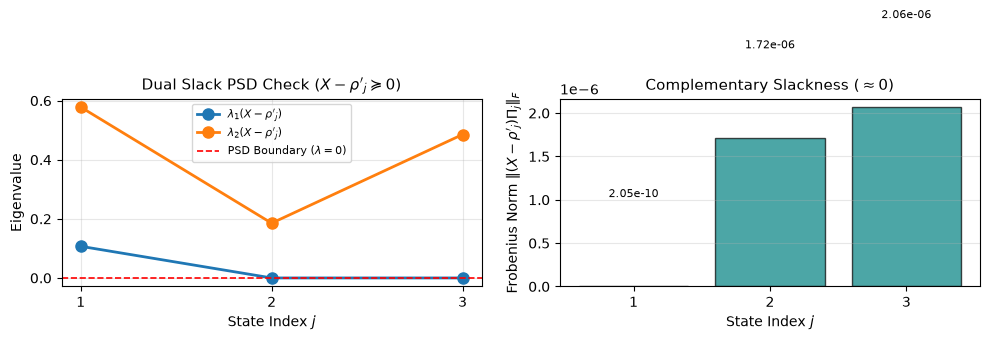

In [4]:
fig_opt = visualization.plot_optimality_verification(result_cvxpy)
plt.show()


## 4. Dynamic & Arbitrary State Discrimination

The implementation is **fully dynamic** and supports:
1. **Arbitrary number of states ($m \ge 2$)**
2. **Arbitrary Hilbert space dimensions ($n \ge 2$: Qubits, Qutrits, Qudits)**
3. **Pure states (kets $|\psi\rangle$) or mixed states (density matrices $\rho$)**
4. **Complex-valued amplitudes**
5. **Non-uniform prior probabilities**

Let's demonstrate several canonical quantum information ensembles:

### 4.1. Binary States ($m=2$) vs. Analytical Helstrom Bound
For $m=2$, the exact analytical Helstrom bound is:
$$P_s = \frac{1}{2}\left(1 + \|\xi_1 \rho_1 - \xi_2 \rho_2\|_1\right)$$


In [5]:
# Create two non-orthogonal states with angle 2*theta
theta = np.pi / 6.0  # 30 degrees
psi1 = np.array([np.cos(theta), np.sin(theta)], dtype=np.complex128)
psi2 = np.array([np.cos(theta), -np.sin(theta)], dtype=np.complex128)
priors_binary = [0.35, 0.65]

disc_binary = QuantumStateDiscriminator(states=[psi1, psi2], probabilities=priors_binary)
res_binary = disc_binary.solve()

print(f"SDP Numerical Success Prob:    {res_binary.success_probability:.8f}")
print(f"Analytical Helstrom Bound:      {res_binary.helstrom_bound:.8f}")
print(f"Difference:                     {abs(res_binary.success_probability - res_binary.helstrom_bound):.2e}")
print(f"Optimality Verified:            {res_binary.is_optimal}")


SDP Numerical Success Prob:    0.93945989
Analytical Helstrom Bound:      0.93945990
Difference:                     6.72e-09
Optimality Verified:            True


### 4.2. Symmetric Trine States ($m=3, n=2$)
Three symmetric states separated by $120^\circ$ on the real plane:
$$|\psi_k\rangle = \cos\left(\frac{2\pi k}{3}\right)|0\rangle + \sin\left(\frac{2\pi k}{3}\right)|1\rangle, \quad k=0,1,2$$
With equal priors, the theoretical maximum detection probability is exactly $P_s = \frac{2}{3} \approx 0.666667$.


In [6]:
trine, trine_probs = states.trine_states()
disc_trine = QuantumStateDiscriminator(states=trine, probabilities=trine_probs)
res_trine = disc_trine.solve()

print(f"Trine States Success Probability: {res_trine.success_probability:.6f} (Expected: {2/3:.6f})")
print(f"Optimality Verified:              {res_trine.is_optimal}")


Trine States Success Probability: 0.666667 (Expected: 0.666667)
Optimality Verified:              True


### 4.3. Standard BB84 States ($m=4, n=2$)
Four states from two mutually unbiased bases: $\{|0\rangle, |1\rangle, |+\rangle, |-\rangle\}$.
Theoretical maximum success probability with uniform priors is $P_s = \frac{1}{2} = 0.500000$.


In [7]:
bb84, bb84_probs = states.bb84_states()
disc_bb84 = QuantumStateDiscriminator(states=bb84, probabilities=bb84_probs)
res_bb84 = disc_bb84.solve()

print(f"BB84 States Success Probability:  {res_bb84.success_probability:.6f} (Expected: 0.500000)")
print(f"Optimality Verified:              {res_bb84.is_optimal}")


BB84 States Success Probability:  0.500000 (Expected: 0.500000)
Optimality Verified:              True


### 4.4. Higher Dimensions: Dynamic Qutrit ($n=3$) & Qudit ($n=4$) Ensembles
We can dynamically generate and discriminate random Haar pure states or mixed states in arbitrary dimensions:


In [8]:
# 4 Random Qutrit pure states (Dimension n=3)
qutrits, qutrit_probs = states.random_pure_states(num_states=4, dimension=3, seed=42)
disc_qutrit = QuantumStateDiscriminator(states=qutrits, probabilities=qutrit_probs)
res_qutrit = disc_qutrit.solve()

print(f"Qutrit Ensemble (m=4, n=3) -> Optimal Ps: {res_qutrit.success_probability:.6f}, Optimal: {res_qutrit.is_optimal}")

# 5 Random Qudit mixed states (Dimension n=4)
qudits, qudit_probs = states.random_mixed_states(num_states=5, dimension=4, seed=42)
disc_qudit = QuantumStateDiscriminator(states=qudits, probabilities=qudit_probs)
res_qudit = disc_qudit.solve()

print(f"Qudit Mixed Ensemble (m=5, n=4) -> Optimal Ps: {res_qudit.success_probability:.6f}, Optimal: {res_qudit.is_optimal}")


Qutrit Ensemble (m=4, n=3) -> Optimal Ps: 0.599676, Optimal: True


Qudit Mixed Ensemble (m=5, n=4) -> Optimal Ps: 0.397196, Optimal: True


d:\Quantum Projects\Paper_Implementation\quantum_state_discrimination\core.py:242: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  problem.solve(solver=chosen_solver, **solve_kwargs)


### 4.5. Mixed State Discrimination under Depolarizing Noise
We can analyze how environmental decoherence affects distinguishability:
$$\mathcal{E}(\rho) = (1 - p)\rho + p \frac{I}{d}$$


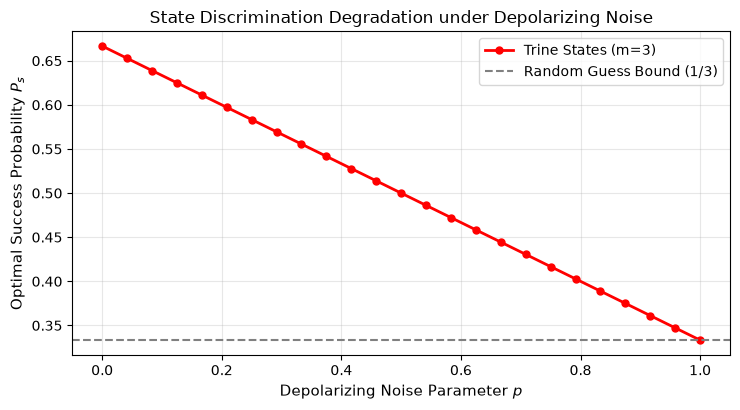

In [9]:
noise_levels = np.linspace(0.0, 1.0, 25)
trine_noisy_ps = []

for p in noise_levels:
    noisy_states = states.add_depolarizing_noise(trine, noise_parameter_p=p)
    disc_noisy = QuantumStateDiscriminator(states=noisy_states, probabilities=trine_probs)
    res_noisy = disc_noisy.solve()
    trine_noisy_ps.append(res_noisy.success_probability)

plt.figure(figsize=(7.5, 4.2))
plt.plot(noise_levels, trine_noisy_ps, 'r-o', markersize=5, linewidth=2, label="Trine States (m=3)")
plt.axhline(1.0 / 3.0, color='gray', linestyle='--', label="Random Guess Bound (1/3)")
plt.xlabel("Depolarizing Noise Parameter $p$", fontsize=11)
plt.ylabel("Optimal Success Probability $P_s$", fontsize=11)
plt.title("State Discrimination Degradation under Depolarizing Noise", fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


## 5. Visualizations: 3D Bloch Sphere & Parameter Sweeps

### 5.1. 3D Bloch Sphere Projection
For single-qubit states ($n=2$), we visualize the state vectors $|\psi_j\rangle$ and the directional POVM measurement elements $\Pi_j$ on the Bloch sphere:


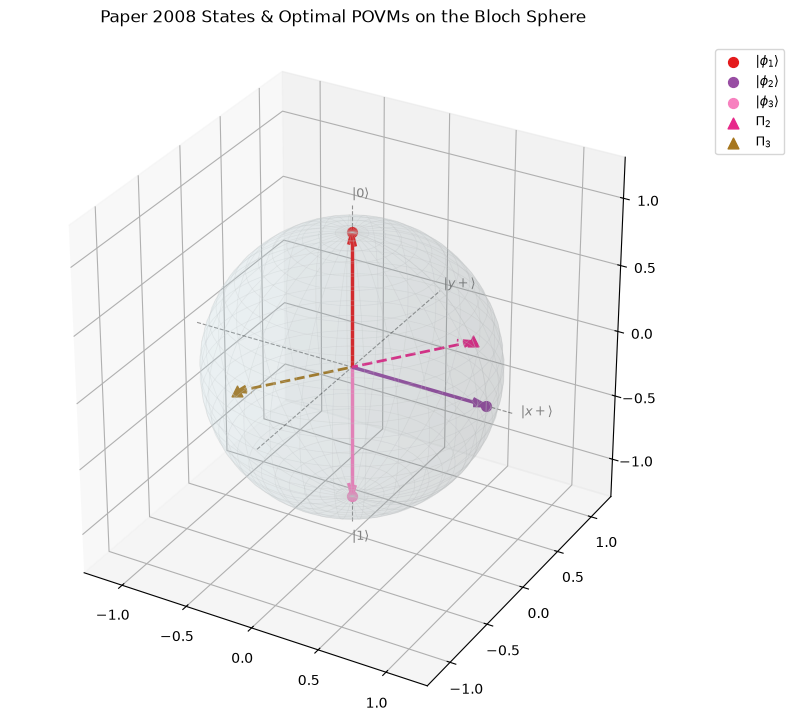

In [10]:
fig_bloch = visualization.plot_bloch_sphere(
    states=raw_states,
    povms=result_cvxpy.povm_operators,
    state_labels=[r"$|\phi_1\rangle$", r"$|\phi_2\rangle$", r"$|\phi_3\rangle$"],
    povm_labels=[r"$\Pi_1$ (Null)", r"$\Pi_2$", r"$\Pi_3$"],
    title="Paper 2008 States & Optimal POVMs on the Bloch Sphere"
)
plt.show()


### 5.2. Prior Probability Sweep
As we vary the prior probability $\xi_2$ of $|\phi_2\rangle$ from $0$ to $1$, the optimal detection strategy smoothly transitions:


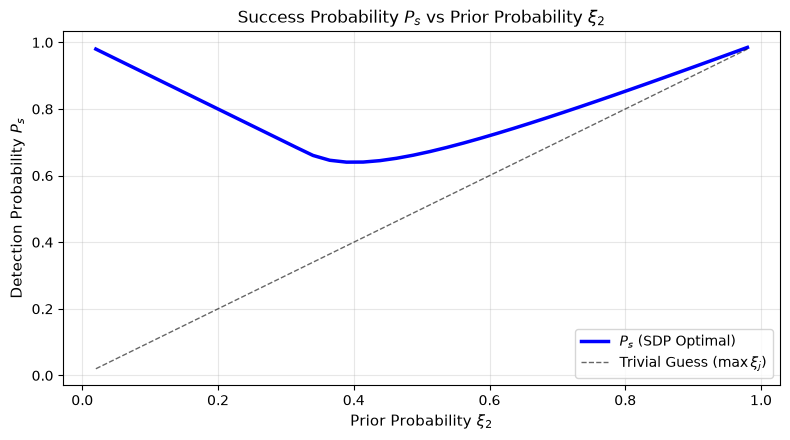

In [11]:
prior_sweep = np.linspace(0.02, 0.98, 40)
fig_sweep = visualization.plot_prior_probability_sweep(
    states=raw_states,
    prior_ratios=prior_sweep,
    target_idx=1,
    title=r"Success Probability $P_s$ vs Prior Probability $\xi_2$"
)
plt.show()


## 6. Interactive Dynamic Exploration (IPyWidgets)

Use the interactive sliders below to dynamically adjust prior probabilities $\xi_1, \xi_2, \xi_3$ and state orientation $\theta$ to observe real-time recalculation of the optimal POVMs and success probability $P_s$:


In [12]:
def interactive_discrimination_demo(xi1, xi2, xi3, angle_deg):
    theta = np.deg2rad(angle_deg)
    
    # Dynamic states
    s1 = np.array([1.0, 0.0], dtype=np.complex128)
    s2 = np.array([np.cos(theta), np.sin(theta)], dtype=np.complex128)
    s3 = np.array([0.0, 1.0], dtype=np.complex128)
    
    priors = [xi1, xi2, xi3]
    disc = QuantumStateDiscriminator(states=[s1, s2, s3], probabilities=priors, normalize_probs=True)
    res = disc.solve()
    
    print(f"Normalized Priors:   xi = [{disc.prior_probabilities[0]:.3f}, {disc.prior_probabilities[1]:.3f}, {disc.prior_probabilities[2]:.3f}]")
    print(f"Optimal Success Ps:  {res.success_probability:.6f} ({res.success_probability*100:.2f}%)")
    print(f"Optimality Verified: {res.is_optimal}")
    print("-" * 50)
    for j, p in enumerate(res.povm_operators):
        tr_val = np.real(np.trace(p))
        print(f"POVM Pi_{j+1} (Weight = {tr_val:.3f}):")
        print(np.round(np.real(p), 3))

# Interactive controls
xi1_slider = widgets.FloatSlider(value=0.1, min=0.01, max=1.0, step=0.05, description=r'$\xi_1$')
xi2_slider = widgets.FloatSlider(value=0.6, min=0.01, max=1.0, step=0.05, description=r'$\xi_2$')
xi3_slider = widgets.FloatSlider(value=0.3, min=0.01, max=1.0, step=0.05, description=r'$\xi_3$')
angle_slider = widgets.FloatSlider(value=45.0, min=5.0, max=85.0, step=5.0, description=r'$\theta$ (deg)')

out = widgets.interactive_output(
    interactive_discrimination_demo,
    {'xi1': xi1_slider, 'xi2': xi2_slider, 'xi3': xi3_slider, 'angle_deg': angle_slider}
)

display(widgets.VBox([widgets.HBox([xi1_slider, xi2_slider]), widgets.HBox([xi3_slider, angle_slider]), out]))


---
## Summary of Enhancements

1. **State-of-the-Art Quantum Libraries**: Integrated **CVXPY 1.9+**, **Toqito 1.3+**, and **QuTiP 5.3+** with modern complex Hermitian SDP cone constraints (`>> 0`).
2. **Dynamic Quantum States**: Fully un-hardcoded input pipelines supporting arbitrary dimensions $n$, arbitrary ensemble sizes $m$, pure and mixed states, complex amplitudes, and custom priors.
3. **Rigorous Optimality Verification**: Automated checking of dual slack positive semidefiniteness ($X - \xi_j \rho_j \succeq 0$), complementary slackness ($(X - \xi_j \rho_j)\Pi_j = 0$), and duality gaps.
4. **Interactive Exploration & 3D Visualizations**: Built-in 3D Bloch sphere projections, decoherence curves, and live IPyWidgets parameter exploration.
